# 04 Sentence-BERT: matching on meaning

Notebook 03 compares models that match **words**. They miss jobs that mean the same
thing but use different words. For example, an applicant who wanted a kindergarten
teacher job was invited to an after-school teacher job, and TF-IDF counted that as a miss.

Sentence-BERT turns each text into a list of numbers (an embedding) so that texts with
similar **meaning** end up close together, even when they share no words. We use a
multilingual model that reads Russian directly, so no translation is needed.

| Model | How it picks jobs |
|---|---|
| M6 Sentence-BERT | compares the meaning of the resume with the meaning of each job |
| M7 Sentence-BERT + region | M6, but jobs in the applicant's own region come first |
| M8 Hybrid + region | mixes the TF-IDF score and the Sentence-BERT score, region first |

**Research question for this notebook:** does matching on meaning (M7) beat matching on
words (M5) when both use the same region filter?

Everything else is the same as notebook 03: the same clean file, the same test
applicants, the same job pool and the same scoring. So the numbers can be compared directly.

> **Stage 1, original study (restored).** M6 Sentence-BERT, M7 with region, and the M8 hybrid, with saved outputs.
> Metric tables are written to `results/baselines/` (the historical reference). The current authoritative results are in `results/final/`.
> The saved embeddings in `clean/` are reused only if their row counts match the current clean file; otherwise they are encoded again.

## How to run this on Google Colab

Sentence-BERT needs a newer version of PyTorch than notebooks 01 to 03, and it runs much
faster on a GPU. Google Colab gives a free GPU.

1. Upload the project folder to Google Drive as `MyDrive/job-recommendation/`.
   Only `clean/` and `results/` are needed, the raw `datasets/` file is not.
2. Open this notebook in Colab (in Drive: right click, Open with, Google Colaboratory).
3. Choose **Runtime, Change runtime type, T4 GPU**.
4. Choose **Runtime, Run all**. Allow Colab to access Google Drive when asked.

It takes about 5 to 10 minutes on a GPU. The embeddings are saved, so a second run is faster.

## 0. Setup

In [6]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

# Change this if you put the project somewhere else in Google Drive
DRIVE_PROJECT = "/content/drive/MyDrive/job-recommendation"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(DRIVE_PROJECT)
    print("running on Google Colab")
except ImportError:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    print("running on this computer")

print("project folder:", os.getcwd())
os.makedirs("results/baselines", exist_ok=True)
os.makedirs("figures", exist_ok=True)

# same settings as notebook 03, so we get the same test applicants
K_LIST     = [5, 10, 20]
TEST_SHARE = 0.20
USE_SKILLS = True
SEED       = 42

running on this computer
project folder: /Users/anantaupadhyaya/Downloads/job-recommendation-salary-analyzer


In [7]:
# Sentence-BERT setup: Hugging Face key and GPU
import os

# PyTorch use the CPU for any operation the GPU does not support.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import getpass
from pathlib import Path

# ---- Hugging Face key 
# Looked up in this order:
#   1. the HF_TOKEN environment variable
#   2. the file .hf_token in the project folder (listed in .gitignore, never uploaded to Git)
#   3. asked once here; you can choose to save it to .hf_token
# The key is never printed.
TOKEN_FILE = Path(".hf_token")
hf_token = os.environ.get("HF_TOKEN", "").strip()
if not hf_token and TOKEN_FILE.exists():
    hf_token = TOKEN_FILE.read_text().strip()
if not hf_token:
    hf_token = getpass.getpass("Hugging Face key (press Enter to skip): ").strip()
    if hf_token and input("Save it in .hf_token for next time? [y/N] ").strip().lower() == "y":
        TOKEN_FILE.write_text(hf_token + "\n")
        TOKEN_FILE.chmod(0o600)   # only you can read it
        print("saved in", TOKEN_FILE.resolve(), "(ignored by Git)")
if hf_token:
    os.environ["HF_TOKEN"] = hf_token   # huggingface_hub and sentence-transformers read this
    print("Hugging Face key: set")
else:
    print("Hugging Face key: not set (public models still download, with lower rate limits)")

# ---- Sentence-BERT -------------------------------------------------------------
# Sentence-BERT is usually already installed on Colab; install it if not
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"])
    from sentence_transformers import SentenceTransformer

# ---- GPU -----------------------------------------------------------------------
import torch
if torch.cuda.is_available():             # NVIDIA GPU (Colab T4, Windows/Linux PC)
    DEVICE = "cuda"
elif torch.backends.mps.is_available():   # Apple Silicon GPU (M1/M2/M3/M4 Mac)
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("torch :", torch.__version__)
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")
if DEVICE == "cpu":
    print("No GPU found. It still works, but takes about 30 minutes.")
    print("On Colab: Runtime, Change runtime type, T4 GPU.")


Hugging Face key: set
torch : 2.15.0
device: mps 


## 1. Load the clean data and rebuild the same test set as notebook 03

This part copies notebook 03 on purpose. The same file, the same seed and the same steps
give exactly the same 2,806 test applicants.

In [8]:
df = pd.read_csv("clean/d4_clean.csv", encoding="utf-8-sig",
                 keep_default_na=False, low_memory=False)
df["is_positive"] = df["is_positive"].astype(int)

def clean_title(titles):
    return (titles.str.lower()
                  .str.replace(r"[^a-zа-яё0-9\s]", " ", regex=True)
                  .str.split().str.join(" "))

def region_key(regions):
    # "Томская область, Колпашевский район, г Колпашево" -> "томская область"
    return (regions.astype(str)
                   .str.split(",").str[0]
                   .str.lower()
                   .str.replace("-", " ")
                   .str.replace(r"^(город|г)\s+", "", regex=True)
                   .str.split().str.join(" "))

# the job pool and the groups of identical postings
jobs = df.drop_duplicates("idVacancy").reset_index(drop=True)
job_row = pd.Series(jobs.index, index=jobs["idVacancy"])
N_JOBS = len(jobs)

group_key = clean_title(jobs["vacancyName"]) + " | " + region_key(jobs["regionName"])
jobs["group"] = pd.factorize(group_key)[0]
group = jobs["group"].to_numpy()

# the same train and test split as notebook 03
eval_ids = np.sort(df.loc[df["in_eval_set"].astype(int) == 1, "idCv"].unique())
rng = np.random.default_rng(SEED)
shuffled = rng.permutation(eval_ids)
n_test = int(len(shuffled) * TEST_SHARE)
test_ids  = np.sort(shuffled[:n_test])
train_ids = np.sort(shuffled[n_test:])

test = df[df["idCv"].isin(test_ids)].drop_duplicates("idCv")
test = test.set_index("idCv").loc[test_ids].reset_index()

invited = df[(df["is_positive"] == 1) & df["idCv"].isin(test_ids)]
answers = invited.groupby("idCv")["idVacancy"].apply(list)
gold_rows   = [[job_row[v] for v in answers[c]] for c in test["idCv"]]
gold_groups = [sorted(set(group[r] for r in rows)) for rows in gold_rows]

# regions as numbers
all_regions = pd.concat([region_key(jobs["regionName"]), region_key(test["localityName"])])
region_id = {name: i for i, name in enumerate(all_regions.unique())}
job_region = region_key(jobs["regionName"]).map(region_id).to_numpy()
cv_region  = region_key(test["localityName"]).map(region_id).to_numpy()

print(f"jobs in the pool: {N_JOBS:,}")
print(f"test applicants : {len(test):,}")

jobs in the pool: 43,756
test applicants : 2,806


## 2. Scoring tools (same as notebook 03)

In [9]:
def evaluate(ranked_lists, gold_lists):
    result = {}
    for k in K_LIST:
        recall, precision, ndcg = [], [], []
        for ranked, gold in zip(ranked_lists, gold_lists):
            gold = set(gold)
            hits = [1 if item in gold else 0 for item in list(ranked)[:k]]

            recall.append(sum(hits) / len(gold))
            precision.append(sum(hits) / k)

            dcg   = sum(h / np.log2(i + 2) for i, h in enumerate(hits))
            ideal = sum(1 / np.log2(i + 2) for i in range(min(k, len(gold))))
            ndcg.append(dcg / ideal)

        result[f"Recall@{k}"]    = np.mean(recall)
        result[f"Precision@{k}"] = np.mean(precision)
        result[f"NDCG@{k}"]      = np.mean(ndcg)
    return result

def drop_repeats(top_rows, k=max(K_LIST)):
    # keep the first posting of each group, so the list has no identical postings
    lists = []
    for rows in top_rows:
        seen, kept = set(), []
        for r in rows:
            if group[r] not in seen:
                seen.add(group[r])
                kept.append(group[r])
            if len(kept) == k:
                break
        lists.append(kept)
    return lists

def top_jobs(Q, D, keep=300, same_region_first=False):
    # works for TF-IDF (sparse) and Sentence-BERT (dense) scores
    best = []
    for start in range(0, Q.shape[0], 250):
        scores = Q[start:start + 250] @ D.T
        if hasattr(scores, "toarray"):
            scores = scores.toarray()
        if same_region_first:
            other = cv_region[start:start + 250, None] != job_region[None, :]
            scores[other] -= 10            # jobs in other regions go to the bottom
        best.append(np.argsort(-scores, axis=1)[:, :keep])
    return np.vstack(best)

top = {}

## 3. Rebuild M5 (TF-IDF + region) for a direct comparison

We need M5's list for every applicant to compare it with Sentence-BERT person by person.
If the number below matches notebook 03, the two notebooks use the same test set.

In [10]:
def make_text(title, body, skills):
    text = (clean_title(title) + " ") * 3 + body
    if USE_SKILLS:
        text = text + " " + skills
    return text.str.strip()

jobs_doc   = make_text(jobs["vacancyName"], jobs["job_text"], jobs["job_skills"])
test_query = make_text(test["positionName"], test["cv_text"], test["cv_skills"])

tfidf = TfidfVectorizer(min_df=3, max_features=120_000, sublinear_tf=True, dtype=np.float32)
D_text = tfidf.fit_transform(jobs_doc)
Q_text = tfidf.transform(test_query)

top["M5 TF-IDF text + region"] = top_jobs(Q_text, D_text, same_region_first=True)

m5 = evaluate(drop_repeats(top["M5 TF-IDF text + region"]), gold_groups)["Recall@10"]
print(f"M5 grouped Recall@10 here: {m5:.4f}")

if Path("results/baselines/metrics_grouped.csv").exists():
    saved = pd.read_csv("results/baselines/metrics_grouped.csv", index_col=0)
    if "M5 TF-IDF text + region" in saved.index:
        print(f"M5 grouped Recall@10 in notebook 03: {saved.loc['M5 TF-IDF text + region', 'Recall@10']:.4f}")
        print("These two numbers should be the same.")

M5 grouped Recall@10 here: 0.4558
M5 grouped Recall@10 in notebook 03: 0.4558
These two numbers should be the same.


## 4. Encode every job and every test applicant with Sentence-BERT

`paraphrase-multilingual-MiniLM-L12-v2` is a small multilingual model that understands
Russian. It reads up to about 128 word pieces, so we give it the start of each text,
where the job title and the main duties are.

The embeddings are saved in `clean/`, so running the notebook again skips this step.

In [11]:
MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"
# a larger, slower and usually stronger option: "paraphrase-multilingual-mpnet-base-v2"

MAX_CHARS = 400   # the start of each text, where the title and main duties are

job_input  = jobs["job_text"].str.slice(0, MAX_CHARS).tolist()
test_input = test["cv_text"].str.slice(0, MAX_CHARS).tolist()

job_file  = f"clean/sbert_jobs_{MODEL_NAME}.npy"
test_file = f"clean/sbert_test_{MODEL_NAME}.npy"

job_emb = test_emb = None
if Path(job_file).exists() and Path(test_file).exists():
    job_emb  = np.load(job_file)
    test_emb = np.load(test_file)
    # only reuse the saved embeddings if they match the current clean file
    if job_emb.shape[0] != len(job_input) or test_emb.shape[0] != len(test_input):
        print("saved embeddings do not match the current clean file; encoding again")
        job_emb = test_emb = None
    else:
        print("loaded saved embeddings")
if job_emb is None:
    model = SentenceTransformer(MODEL_NAME, device=DEVICE)
    t0 = time.time()
    # normalize_embeddings=True makes a dot product equal to cosine similarity
    job_emb  = model.encode(job_input, batch_size=128, show_progress_bar=True,
                            normalize_embeddings=True, convert_to_numpy=True)
    test_emb = model.encode(test_input, batch_size=128, show_progress_bar=True,
                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(job_file, job_emb)
    np.save(test_file, test_emb)
    print(f"encoded in {time.time() - t0:.0f}s and saved")

job_emb  = job_emb.astype(np.float32)
test_emb = test_emb.astype(np.float32)
print("jobs :", job_emb.shape)
print("tests:", test_emb.shape)

loaded saved embeddings
jobs : (43756, 384)
tests: (2806, 384)


## 5. M6 Sentence-BERT and M7 Sentence-BERT + region

In [12]:
t0 = time.time()
top["M6 Sentence-BERT"]          = top_jobs(test_emb, job_emb)
top["M7 Sentence-BERT + region"] = top_jobs(test_emb, job_emb, same_region_first=True)
print(f"time: {time.time() - t0:.0f}s")

time: 31s


## 6. M8 Hybrid: words and meaning together

TF-IDF and Sentence-BERT find different people (Section 8 shows how many), so we mix
their scores:

**hybrid score = weight x TF-IDF score + (1 - weight) x Sentence-BERT score**

The two scores are on different scales, so we first rescale each applicant's scores to
mean 0 and spread 1 (a z-score). A weight of 1 is pure TF-IDF, a weight of 0 is pure
Sentence-BERT.

**The weight is chosen on 1,000 training applicants, never on the test applicants.**
Choosing it on the test set would be cheating, because the test set would then help
build the model it is supposed to judge.

In [13]:
# 1,000 training applicants used only to choose the weight
rng_val = np.random.default_rng(SEED)
val_ids = np.sort(rng_val.choice(train_ids, size=min(1000, len(train_ids)), replace=False))

val = df[df["idCv"].isin(val_ids)].drop_duplicates("idCv")
val = val.set_index("idCv").loc[val_ids].reset_index()

val_invited = df[(df["is_positive"] == 1) & df["idCv"].isin(val_ids)]
val_answers = val_invited.groupby("idCv")["idVacancy"].apply(list)
val_gold    = [sorted(set(group[job_row[v]] for v in val_answers[c])) for c in val["idCv"]]

val_region = (region_key(val["localityName"]).map(region_id)
              .fillna(-1).astype(int).to_numpy())

# TF-IDF and Sentence-BERT versions of the validation resumes
Q_val_words = tfidf.transform(make_text(val["positionName"], val["cv_text"], val["cv_skills"]))

val_file = f"clean/sbert_val_{MODEL_NAME}.npy"
Q_val_meaning = np.load(val_file) if Path(val_file).exists() else None
if Q_val_meaning is not None and Q_val_meaning.shape[0] != len(val):
    print("saved validation embeddings do not match the current clean file; encoding again")
    Q_val_meaning = None
if Q_val_meaning is None:
    if "model" not in globals():
        model = SentenceTransformer(MODEL_NAME, device=DEVICE)
    Q_val_meaning = model.encode(val["cv_text"].str.slice(0, MAX_CHARS).tolist(), batch_size=128,
                                 show_progress_bar=True, normalize_embeddings=True,
                                 convert_to_numpy=True)
    np.save(val_file, Q_val_meaning)
Q_val_meaning = Q_val_meaning.astype(np.float32)

print(f"validation applicants: {len(val):,} (all from the training side)")

validation applicants: 1,000 (all from the training side)


In [14]:
def zscore(scores):
    # rescale each applicant's scores to mean 0 and spread 1
    return (scores - scores.mean(axis=1, keepdims=True)) / (scores.std(axis=1, keepdims=True) + 1e-9)

def top_jobs_hybrid(Q_words, Q_meaning, regions, weight, keep=300):
    best = []
    for start in range(0, Q_words.shape[0], 250):
        end = start + 250
        words   = zscore((Q_words[start:end] @ D_text.T).toarray())
        meaning = zscore(Q_meaning[start:end] @ job_emb.T)
        scores  = weight * words + (1 - weight) * meaning
        other = regions[start:end, None] != job_region[None, :]
        scores[other] -= 1_000_000        # jobs in other regions go to the bottom
        best.append(np.argsort(-scores, axis=1)[:, :keep])
    return np.vstack(best)

WEIGHTS = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
curve = {}
for w in WEIGHTS:
    rows = top_jobs_hybrid(Q_val_words, Q_val_meaning, val_region, w)
    curve[w] = evaluate(drop_repeats(rows), val_gold)["Recall@10"]
    print(f"weight {w:.1f}  validation Recall@10 = {curve[w]:.4f}")

BEST_WEIGHT = max(curve, key=curve.get)
print()
print(f"best weight on the validation applicants: {BEST_WEIGHT}")

weight 0.0  validation Recall@10 = 0.3620
weight 0.2  validation Recall@10 = 0.4380
weight 0.4  validation Recall@10 = 0.4345
weight 0.5  validation Recall@10 = 0.4425
weight 0.6  validation Recall@10 = 0.4365
weight 0.8  validation Recall@10 = 0.4380
weight 1.0  validation Recall@10 = 0.4395

best weight on the validation applicants: 0.5


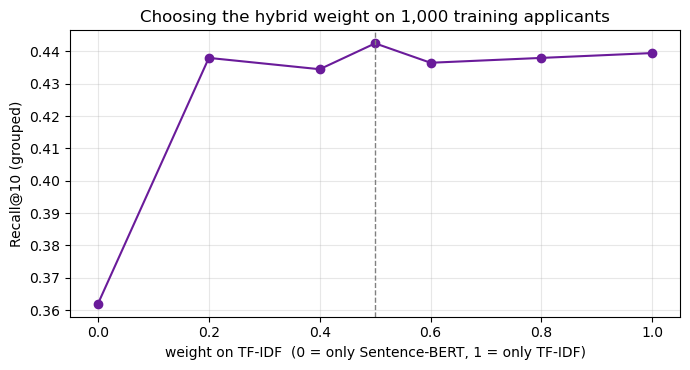

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(curve.keys()), list(curve.values()), marker="o", color="#6a1b9a")
ax.axvline(BEST_WEIGHT, color="grey", ls="--", lw=1)
ax.set_xlabel("weight on TF-IDF  (0 = only Sentence-BERT, 1 = only TF-IDF)")
ax.set_ylabel("Recall@10 (grouped)")
ax.set_title("Choosing the hybrid weight on 1,000 training applicants")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/hybrid_weight.png", dpi=150)
plt.show()

In [16]:
# now use the chosen weight on the test applicants, once
t0 = time.time()
top["M8 Hybrid + region"] = top_jobs_hybrid(Q_text, test_emb, cv_region, BEST_WEIGHT)
print(f"M8 uses weight {BEST_WEIGHT} on TF-IDF   time: {time.time() - t0:.0f}s")

M8 uses weight 0.5 on TF-IDF   time: 13s


## 7. Results for all models

M0 to M5 come from notebook 03 (`results/baselines/metrics_*.csv`). M6, M7 and M8 are added here.

In [17]:
columns = [f"{m}@{k}" for k in K_LIST for m in ["Recall", "Precision", "NDCG"]]

new_strict, new_grouped = {}, {}
for name in ["M6 Sentence-BERT", "M7 Sentence-BERT + region", "M8 Hybrid + region"]:
    rows = top[name]
    new_strict[name]  = evaluate([r[:max(K_LIST)] for r in rows], gold_rows)
    new_grouped[name] = evaluate(drop_repeats(rows), gold_groups)

new_strict  = pd.DataFrame(new_strict).T[columns]
new_grouped = pd.DataFrame(new_grouped).T[columns]

old_strict  = pd.read_csv("results/baselines/metrics_strict.csv", index_col=0)
old_grouped = pd.read_csv("results/baselines/metrics_grouped.csv", index_col=0)

strict  = pd.concat([old_strict, new_strict])
grouped = pd.concat([old_grouped, new_grouped])

pd.set_option("display.float_format", "{:.4f}".format)
print("GROUPED: same title in the same region counts, repeated postings removed")
grouped

GROUPED: same title in the same region counts, repeated postings removed


,Recall@5,Precision@5,NDCG@5,Recall@10,Precision@10,NDCG@10,Recall@20,Precision@20,NDCG@20
Random,0.0012,0.0003,0.0007,0.0032,0.0004,0.0014,0.0057,0.0003,0.0020
M0 Popularity,0.0282,0.0058,0.0197,0.0449,0.0047,0.0251,0.0775,0.0040,0.0334
M1 TF-IDF title,0.0839,0.0175,0.0519,0.1334,0.0139,0.0680,0.1930,0.0100,0.0833
M2 TF-IDF text,0.0776,0.0163,0.0496,0.1339,0.0139,0.0679,0.2141,0.0112,0.0882
M3 BM25 text,0.0875,0.0184,0.0567,0.1328,0.0139,0.0712,0.2002,0.0104,0.0882
M4 Popularity + region,0.1377,0.0282,0.0992,0.1908,0.0197,0.1162,0.2552,0.0132,0.1325
M5 TF-IDF text + region,0.3926,0.0812,0.3201,0.4558,0.0471,0.3408,0.5199,0.0269,0.3571
M6 Sentence-BERT,0.0435,0.0091,0.0273,0.0709,0.0075,0.0361,0.1084,0.0058,0.0456
M7 Sentence-BERT + region,0.2906,0.0600,0.2098,0.3652,0.0378,0.2340,0.4452,0.0230,0.2544
M8 Hybrid + region,0.3980,0.0823,0.3238,0.4660,0.0482,0.3457,0.5396,0.0279,0.3645


In [18]:
print("STRICT: must find the exact posting")
strict

STRICT: must find the exact posting


,Recall@5,Precision@5,NDCG@5,Recall@10,Precision@10,NDCG@10,Recall@20,Precision@20,NDCG@20
Random,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0007,0.0000,0.0002
M0 Popularity,0.0260,0.0053,0.0177,0.0353,0.0037,0.0208,0.0613,0.0032,0.0273
M1 TF-IDF title,0.0306,0.0066,0.0181,0.0468,0.0050,0.0232,0.0727,0.0038,0.0296
M2 TF-IDF text,0.0261,0.0055,0.0173,0.0447,0.0047,0.0233,0.0736,0.0039,0.0306
M3 BM25 text,0.0282,0.0061,0.0190,0.0451,0.0048,0.0244,0.0694,0.0037,0.0306
M4 Popularity + region,0.1044,0.0215,0.0757,0.1413,0.0146,0.0875,0.1828,0.0095,0.0982
M5 TF-IDF text + region,0.1958,0.0409,0.1381,0.2662,0.0280,0.1614,0.3561,0.0187,0.1844
M6 Sentence-BERT,0.0125,0.0027,0.0081,0.0202,0.0022,0.0105,0.0329,0.0018,0.0138
M7 Sentence-BERT + region,0.1135,0.0237,0.0791,0.1649,0.0174,0.0958,0.2382,0.0125,0.1145
M8 Hybrid + region,0.2023,0.0423,0.1422,0.2749,0.0289,0.1661,0.3686,0.0194,0.1899


In [19]:
base = grouped.loc["Random", "Recall@10"]
print(f"Grouped Recall@10 of random guessing: {base:.4f}")
print()
for name, value in grouped["Recall@10"].drop("Random").sort_values(ascending=False).items():
    print(f"  {name:28s} {value:.4f}   {value / base:6.1f} x random")

Grouped Recall@10 of random guessing: 0.0032

  M8 Hybrid + region           0.4660    145.3 x random
  M5 TF-IDF text + region      0.4558    142.1 x random
  M7 Sentence-BERT + region    0.3652    113.9 x random
  M4 Popularity + region       0.1908     59.5 x random
  M2 TF-IDF text               0.1339     41.7 x random
  M1 TF-IDF title              0.1334     41.6 x random
  M3 BM25 text                 0.1328     41.4 x random
  M6 Sentence-BERT             0.0709     22.1 x random
  M0 Popularity                0.0449     14.0 x random


### The main comparison: words, meaning, or both?

All three use the same region filter. The only difference is how they compare texts.

In [20]:
pair = ["M5 TF-IDF text + region", "M7 Sentence-BERT + region", "M8 Hybrid + region"]
grouped.loc[pair, ["Recall@5", "Recall@10", "Recall@20", "NDCG@10"]]

,Recall@5,Recall@10,Recall@20,NDCG@10
M5 TF-IDF text + region,0.3926,0.4558,0.5199,0.3408
M7 Sentence-BERT + region,0.2906,0.3652,0.4452,0.2340
M8 Hybrid + region,0.3980,0.4660,0.5396,0.3457


### Chart

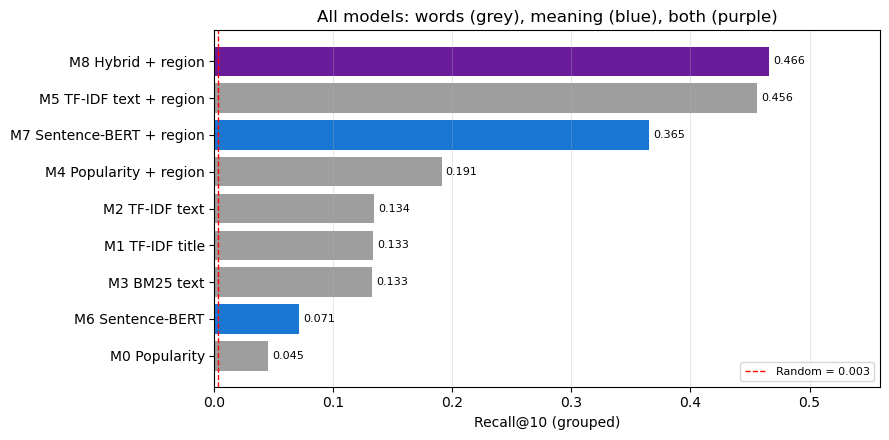

In [21]:
order = grouped.drop("Random")["Recall@10"].sort_values()
colors = ["#6a1b9a" if "Hybrid" in m else "#1976d2" if "Sentence-BERT" in m else "#9e9e9e"
          for m in order.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(order.index, order.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.axvline(base, color="red", ls="--", lw=1, label=f"Random = {base:.3f}")
ax.set_xlabel("Recall@10 (grouped)")
ax.set_title("All models: words (grey), meaning (blue), both (purple)")
ax.set_xlim(0, order.max() * 1.2)
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/all_models_recall.png", dpi=150)
plt.show()

## 8. Person by person: who does each model find?

The average hides an important detail. The two models may find different people,
which is why combining them in M8 can help.

In [22]:
def found_in_top10(name):
    lists = drop_repeats(top[name])
    return np.array([bool(set(lists[i][:10]) & set(gold_groups[i])) for i in range(len(test))])

words   = found_in_top10("M5 TF-IDF text + region")
meaning = found_in_top10("M7 Sentence-BERT + region")

summary = pd.Series({
    "found by both":            int(( words &  meaning).sum()),
    "only TF-IDF (words)":      int(( words & ~meaning).sum()),
    "only Sentence-BERT":       int((~words &  meaning).sum()),
    "found by neither":         int((~words & ~meaning).sum()),
})
print(summary.to_string())
print()
hybrid = found_in_top10("M8 Hybrid + region")
print(f"found by at least one of the two: {(words | meaning).mean():.1%} of test applicants")
print("(the most a perfect mix of the two could reach)")
print()
print(f"M5 TF-IDF alone finds   : {words.mean():.1%}")
print(f"M7 Sentence-BERT finds  : {meaning.mean():.1%}")
print(f"M8 Hybrid finds         : {hybrid.mean():.1%}")

found by both           882
only TF-IDF (words)     417
only Sentence-BERT      166
found by neither       1341

found by at least one of the two: 52.2% of test applicants
(the most a perfect mix of the two could reach)

M5 TF-IDF alone finds   : 46.3%
M7 Sentence-BERT finds  : 37.3%
M8 Hybrid finds         : 47.3%


In [23]:
first_row = jobs.groupby("group").head(1).set_index("group")
lists_words   = drop_repeats(top["M5 TF-IDF text + region"])
lists_meaning = drop_repeats(top["M7 Sentence-BERT + region"])

def show(i, n=10):
    gold = set(gold_groups[i])
    print("=" * 70)
    print(f"applicant wants: {test['positionName_en'].iloc[i]}")
    print("was invited to :", ", ".join(first_row.loc[g, "vacancyName_en"][:40] for g in gold))
    for label, lists in [("TF-IDF", lists_words), ("Sentence-BERT", lists_meaning)]:
        print(f"  {label}:")
        for rank, g in enumerate(lists[i][:n], 1):
            mark = "OK" if g in gold else "  "
            print(f"    {rank}. [{mark}] {first_row.loc[g, 'vacancyName_en'][:50]}")

only_meaning = np.where(~words & meaning)[0]
only_words   = np.where(words & ~meaning)[0]

print("### found only by Sentence-BERT")
for i in only_meaning[:3]:
    show(i)
print()
print("### found only by TF-IDF")
for i in only_words[:2]:
    show(i)

### found only by Sentence-BERT
applicant wants: Loader
was invited to : General labourer
  TF-IDF:
    1. [  ] Loader
    2. [  ] плотник-столяр
    3. [  ] Столяр
    4. [  ] грузчик-экспедитор
    5. [  ] Грузчик (квота)
    6. [  ] грузчик-разнорабочий
    7. [  ] Loader and order picker
    8. [  ] Грузчик 2 разряда
    9. [  ] Стропальщик (грузчик)
    10. [  ] Оператор-грузчик
  Sentence-BERT:
    1. [  ] Loader
    2. [  ] General labourer
    3. [  ] грузчик-экспедитор
    4. [OK] General labourer
    5. [  ] Оператор-грузчик
    6. [  ] Crane operator
    7. [  ] Разнорабочий на производство
    8. [  ] Loader and order picker
    9. [  ] Packer
    10. [  ] машинист крана металлургического производства
applicant wants: Оператор станка
was invited to : Mechanical assembly fitter
  TF-IDF:
    1. [  ] Welder
    2. [  ] Сварщик-оператор полностью механизированной, автом
    3. [  ] Оператор пакетосварочного станка
    4. [  ] электросварщик ручной сварки
    5. [  ] Electric a

## 9. Save

In [24]:
strict.to_csv("results/baselines/metrics_strict_all.csv", encoding="utf-8-sig")
grouped.to_csv("results/baselines/metrics_grouped_all.csv", encoding="utf-8-sig")
summary.to_csv("results/baselines/m5_vs_m7_by_applicant.csv", header=["applicants"], encoding="utf-8-sig")
pd.Series(curve, name="validation Recall@10").to_csv("results/baselines/hybrid_weight.csv", encoding="utf-8-sig")

print("saved:")
for f in ["results/baselines/metrics_strict_all.csv", "results/baselines/metrics_grouped_all.csv",
          "results/baselines/m5_vs_m7_by_applicant.csv", "results/baselines/hybrid_weight.csv",
          "figures/all_models_recall.png", "figures/hybrid_weight.png"]:
    print("  ", f)

saved:
   results/baselines/metrics_strict_all.csv
   results/baselines/metrics_grouped_all.csv
   results/baselines/m5_vs_m7_by_applicant.csv
   results/baselines/hybrid_weight.csv
   figures/all_models_recall.png
   figures/hybrid_weight.png


## How to read the results

1. **M7 vs M5** compares meaning with words. Job titles in this data are written in a
   fairly standard way, so word matching is hard to beat on its own.
2. **Section 8** shows that the two models find different people. Sentence-BERT finds
   applicants whose invited job uses different words from the job they asked for.
3. **M8 vs M5** shows whether mixing the two helps. The weight was chosen on training
   applicants only, so the test result is a fair estimate.